Product Demand Prediction Model Performance
MAE  : 1.74
RMSE : 2.32
R²   : 0.4238

Sample Predictions:
   Actual_Quantity  Predicted_Quantity
0                5                6.54
1                2                4.61
2                3                7.47
3                1                6.65
4               10               12.06
5                7                4.19
6                3                1.79
7                2                1.70
8                7                6.52
9                2                1.72


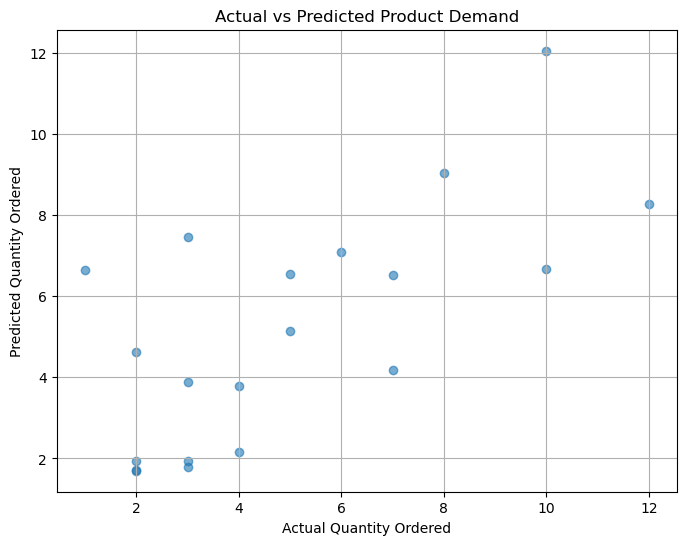

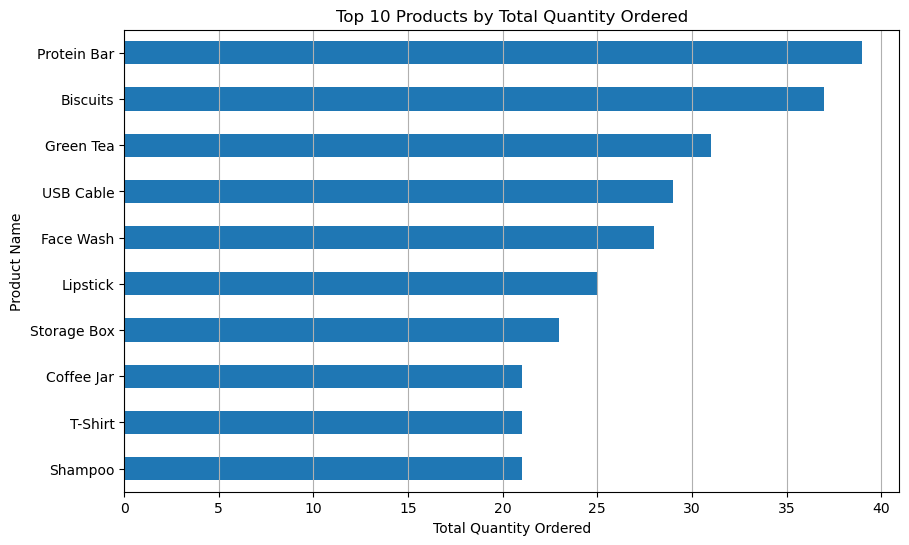

In [1]:
# ==========================================
# PRODUCT DEMAND PREDICTION - FINAL JUPYTER CODE
# Target: QUANTITYORDERED
# ==========================================

# If needed:
# !pip install pandas numpy matplotlib scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -----------------------------
# 1. LOAD DATA
# -----------------------------
file_path = "powerbi_sales_dataset.csv"   # change if needed
df = pd.read_csv(file_path)

# Clean column names
df.columns = df.columns.str.strip()

# -----------------------------
# 2. CHECK REQUIRED COLUMNS
# -----------------------------
required_cols = [
    "ORDERDATE", "CustomerSegment", "Region", "City",
    "ProductName", "Category", "PRICEEACH", "STATUS", "QUANTITYORDERED"
]

missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# -----------------------------
# 3. CLEAN DATA
# -----------------------------
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%d-%b-%y", errors="coerce")
if df["ORDERDATE"].isna().sum() > 0:
    df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], errors="coerce", format="mixed")

df["PRICEEACH"] = pd.to_numeric(df["PRICEEACH"], errors="coerce")
df["QUANTITYORDERED"] = pd.to_numeric(df["QUANTITYORDERED"], errors="coerce")

df = df.dropna(subset=required_cols).copy()

# -----------------------------
# 4. FEATURE ENGINEERING
# -----------------------------
df["OrderMonth"] = df["ORDERDATE"].dt.month
df["OrderQuarter"] = df["ORDERDATE"].dt.quarter
df["OrderYear"] = df["ORDERDATE"].dt.year
df["DayOfWeek"] = df["ORDERDATE"].dt.dayofweek

# Optional: remove extreme outliers in quantity
# df = df[df["QUANTITYORDERED"] <= df["QUANTITYORDERED"].quantile(0.99)]

# -----------------------------
# 5. SELECT FEATURES / TARGET
# -----------------------------
feature_cols = [
    "CustomerSegment", "Region", "City",
    "ProductName", "Category", "PRICEEACH", "STATUS",
    "OrderMonth", "OrderQuarter", "OrderYear", "DayOfWeek"
]

target_col = "QUANTITYORDERED"

X = df[feature_cols]
y = df[target_col]

categorical_cols = [
    "CustomerSegment", "Region", "City",
    "ProductName", "Category", "STATUS"
]

numeric_cols = [
    "PRICEEACH", "OrderMonth", "OrderQuarter", "OrderYear", "DayOfWeek"
]

# -----------------------------
# 6. PREPROCESSING
# -----------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

# -----------------------------
# 7. MODEL PIPELINE
# -----------------------------
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42
    ))
])

# -----------------------------
# 8. TRAIN / TEST SPLIT
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -----------------------------
# 9. TRAIN MODEL
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# 10. PREDICT
# -----------------------------
y_pred = model.predict(X_test)

# -----------------------------
# 11. EVALUATE
# -----------------------------
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Product Demand Prediction Model Performance")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

# -----------------------------
# 12. ACTUAL VS PREDICTED TABLE
# -----------------------------
results_df = pd.DataFrame({
    "Actual_Quantity": y_test.values,
    "Predicted_Quantity": np.round(y_pred, 2)
})

print("\nSample Predictions:")
print(results_df.head(10))

# -----------------------------
# 13. PLOT ACTUAL VS PREDICTED
# -----------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Quantity Ordered")
plt.ylabel("Predicted Quantity Ordered")
plt.title("Actual vs Predicted Product Demand")
plt.grid(True)
plt.show()

# -----------------------------
# 14. DEMAND BY PRODUCT (OPTIONAL SUMMARY)
# -----------------------------
product_demand = (
    df.groupby("ProductName")["QUANTITYORDERED"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
product_demand.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Total Quantity Ordered")
plt.xlabel("Total Quantity Ordered")
plt.ylabel("Product Name")
plt.grid(axis="x")
plt.show()